# Starling: Drift-Aware Retraining for Time-Series Anomaly Detection

Research question: does drift-aware retraining improve time-series anomaly detection compared with static training and periodic retraining?

Data: NASA SMAP/MSL telemetry from [Telemanom](https://github.com/khundman/telemanom). Original files are never modified.

**How to read this notebook.** Every code cell has a short note above it saying *what it does*, *why it matters* and *what output to expect*. Run it from the `Starling/` project root, top to bottom.

| Part | Content | Status |
|---|---|---|
| 1 | Setup and loader check | done |
| 2 | Dataset facts from the audit | done |
| 3 | P-2 and M-6: look at the data | done |
| 4 | Exploratory baseline (centered window, test-calibrated) | done, **not a valid result** |
| 5 | Protocol for a defensible baseline | agreed |
| 6 | Trailing-window deviation, train vs test | in progress |
| 7 | Train-based threshold, scoring, forecasting model, MLflow, retraining strategies | planned |

## 1. Setup

**What it does:** turns on autoreload, imports the libraries, and sets one constant for the data folder.

**Why:** `%autoreload 2` re-imports changed `src/starling/*.py` files automatically, so you don't restart the kernel after every edit. `DATA_DIR` replaces the old `.env` variables (`train_data_dir`, `test_data_dir`, `meta_data`), because `load_channel` already builds those paths from one folder. Fewer moving parts means fewer ways to break.

**Expect:** no output.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from starling.data_load import load_channel

DATA_DIR = "data"  

### Loader check

**What it does:** calls `load_channel` on three channels that behave differently.

**Why:** the loader is the foundation of everything else, so we test its edge cases once, here.
- P-2 has two annotation rows. Both intervals must survive.
- M-6 has one interval.
- T-10 has no annotation row. `load_channel` raises a `ValueError` for it, on purpose. "No label" means *unknown*, not *normal*, and raising an error stops it from silently entering a labeled benchmark.

**Expect:**
```
P-2   train= 2821  test= 8209  intervals=[[5350, 6575], [5300, 6420]]
M-6   train= 1565  test= 2049  intervals=[[1850, 2030]]
T-10  -> excluded (...)
```

In [2]:
for chan in ["P-2", "M-6", "T-10"]:
    try:
        tr, te, iv = load_channel(chan, data_dir=DATA_DIR)
        print(f"{chan:5s} train={len(tr):5d}  test={len(te):5d}  intervals={iv}")
    except ValueError as e:
        print(f"{chan:5s} -> excluded ({e})")

P-2   train= 2821  test= 8209  intervals=[[5350, 6575], [5300, 6420]]
M-6   train= 1565  test= 2049  intervals=[[1850, 2030]]
T-10  -> excluded (T-10 has no annotation row; excluded from labeled benchmark)


## 2. Dataset facts from the audit

These were established earlier and are **observed facts**. No data has been modified.

| Check | Result |
|---|---|
| Training / test channels | 82 / 82, all matching |
| Format | NumPy float64, shape `(timesteps, features)`; target is column 0 |
| Non-finite values | none |
| Annotation rows | 82 rows, 81 unique channels |
| `P-2` | two annotation rows, both preserved (they overlap) |
| `T-10` | no annotation: excluded from the labeled benchmark, **not** assumed normal |
| Target outside `[-1, 1]` | 18 train channels, 21 test channels |
| Constant training target | 16 channels |
| `M-6` | constant training signal at -1; test maximum about 258.11 |

**Open questions (hypotheses, not facts):** why `M-6` differs so much between train and test (data quality, preprocessing, or a real change), and whether any channel shows genuine drift. A train/test difference alone does not establish drift.

## 3. Look at the data

### Plot helper

**What it does:** defines a function that plots a signal and shades every labeled interval red.

**Why:** we plot several channels, so one helper avoids copy-pasting plotting code. Each interval is shaded separately, so overlapping intervals (P-2) look darker where they overlap. Nothing is merged.

**Expect:** no output.

In [3]:
def plot_with_labels(signal, intervals, title):
    plt.figure(figsize=(14, 4))
    plt.plot(signal, linewidth=0.8)
    for start, end in intervals:
        plt.axvspan(start, end, alpha=0.25, color="red")
    plt.title(title)
    plt.xlabel("Time step")
    plt.ylabel("Telemetry value")
    plt.tight_layout()
    plt.show()

### P-2 with its labels

**What it does:** loads P-2 and plots the test signal with both labeled intervals shaded.

**Why:** before any algorithm, look at what an anomaly looks like in this channel. Variable names carry the channel (`test_p2`), so loading M-6 later cannot overwrite them. The old notebook reused `train` and `test` for different channels, so results depended on cell order.

**Expect:** lengths 2821 and 8209. A quiet signal near -0.9, a burst of large spikes from about 5300 to 6400, then quiet again. The red shading starts at 5300 and ends near 6575, a little past the visible burst.

train: 2821 | test: 8209
intervals: [[5350, 6575], [5300, 6420]]


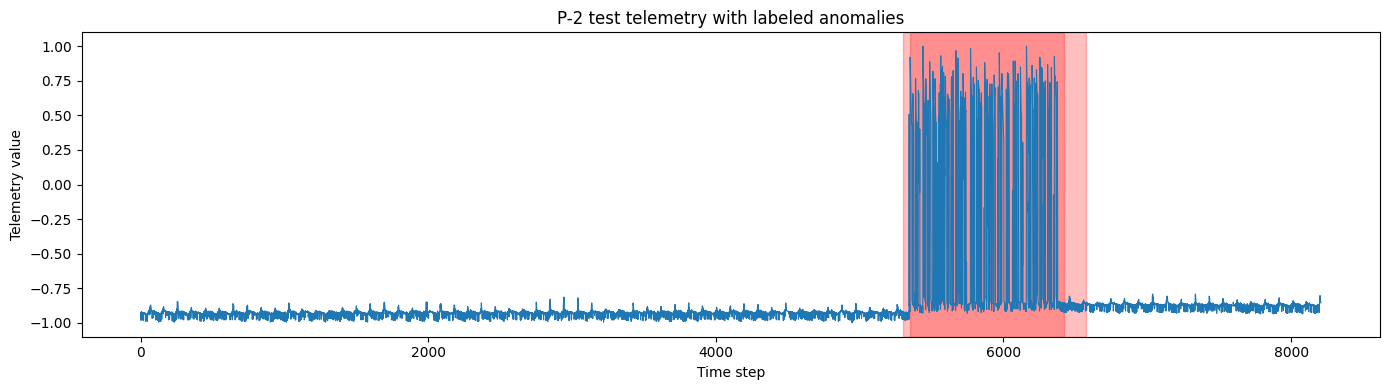

In [4]:
train_p2, test_p2, intervals_p2 = load_channel("P-2", data_dir=DATA_DIR)
print("train:", len(train_p2), "| test:", len(test_p2))
print("intervals:", intervals_p2)

plot_with_labels(test_p2, intervals_p2, "P-2 test telemetry with labeled anomalies")

### M-6: the train/test mismatch

**What it does:** prints summary statistics for the M-6 train and test signals, finds where the test signal first exceeds 1.0, and plots both signals with the label on the test plot.

**Why:** M-6 is the severe case from the audit. We record where the jump happens relative to the labeled interval, but we do **not** explain or fix it yet.

**Expect:** train min = max = -1 and std 0. Test max about 258.11. The label is `[[1850, 2030]]`. Compare the first index above 1.0 with that interval and write down what you see; don't interpret it yet.

train: min -1.0 | max -1.0 | std 0.0
test:  min -1.0 | max 258.1081 | std 37.5856
intervals: [[1850, 2030]]
first test index above 1.0: 1312


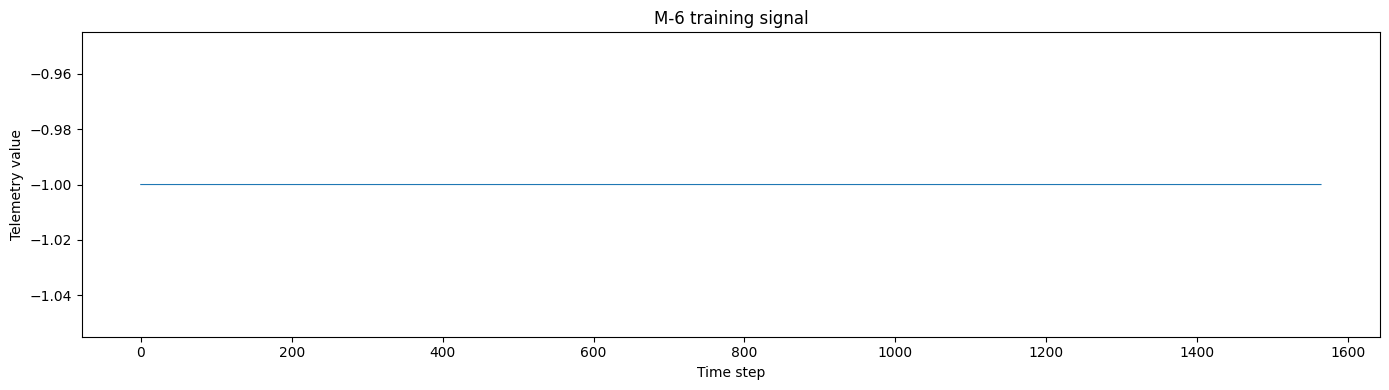

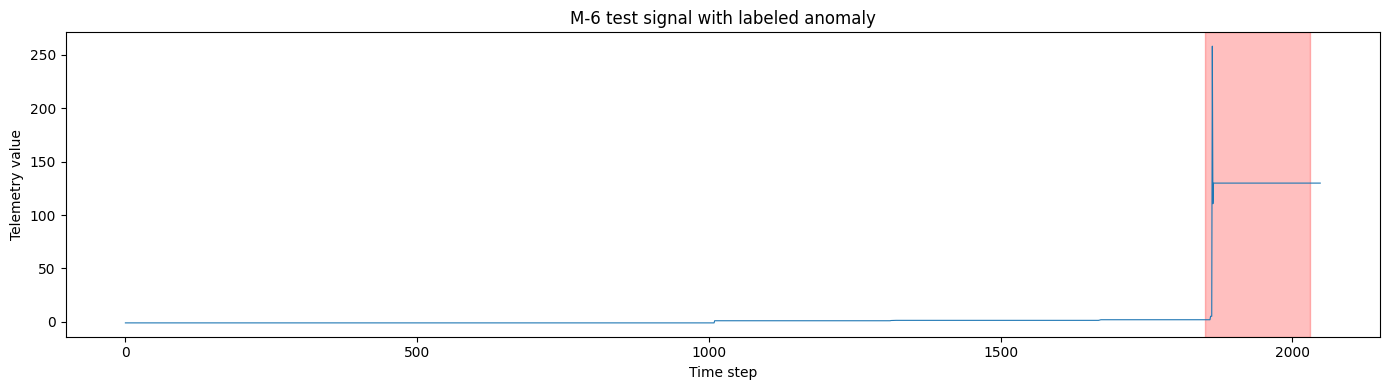

In [5]:
train_m6, test_m6, intervals_m6 = load_channel("M-6", data_dir=DATA_DIR)

print("train: min", train_m6.min(), "| max", train_m6.max(), "| std", train_m6.std())
print("test:  min", test_m6.min(), "| max", round(test_m6.max(), 4), "| std", round(test_m6.std(), 4))
print("intervals:", intervals_m6)

above = np.where(test_m6 > 1.0)[0]
print("first test index above 1.0:", above[0] if len(above) else None)

plot_with_labels(train_m6, [], "M-6 training signal")
plot_with_labels(test_m6, intervals_m6, "M-6 test signal with labeled anomaly")

## 4. Exploratory baseline: rolling median (NOT a valid result)

This section is kept as a research log. It taught us what goes wrong, but its numbers must **not** be reported, for three reasons:

1. **Test-set calibration.** The threshold is computed from the test signal itself, which contains the anomaly. The burst inflates the very statistic used to detect it.
2. **Look-ahead.** `center=True` uses future points, so it can't run on a live stream.
3. **Invented boundaries.** `min_periods=1` builds medians from a handful of points at the edges.

### Compute deviation and threshold

**What it does:** takes the median of a 101-point window around each point, measures the absolute distance of each point from it, then sets a threshold at `median + 6 x 1.4826 x MAD` of those distances and flags points above it.

**Why:** the median ignores a few extreme values, so it follows the "normal" level, and a point far from it is suspicious. MAD (median absolute deviation) is a robust spread estimate; 1.4826 rescales it to match a standard deviation for Gaussian data.

**Expect:** threshold about 0.0583 and 988 flagged points out of 8209.

In [6]:
signal = test_p2
window = 101

rolling_median = pd.Series(signal).rolling(window=window, center=True, min_periods=1).median()
deviation = np.abs(signal - rolling_median.to_numpy())

dev_median = np.median(deviation)
mad = np.median(np.abs(deviation - dev_median))
threshold = dev_median + 6 * 1.4826 * mad
predictions = deviation > threshold

print("threshold:", threshold)
print("flagged:", predictions.sum(), "of", len(signal))

threshold: 0.05827170032374953
flagged: 988 of 8209


### Plot the flagged points

**What it does:** draws the signal and puts a red dot on every flagged point.

**Why:** a number like 988 says nothing about *where* the detector fires. The plot shows it.

**Expect:** dense dots in the burst (about 5350 to 6400) **and** scattered dots across the quiet parts. Those quiet-region dots are the false positives.

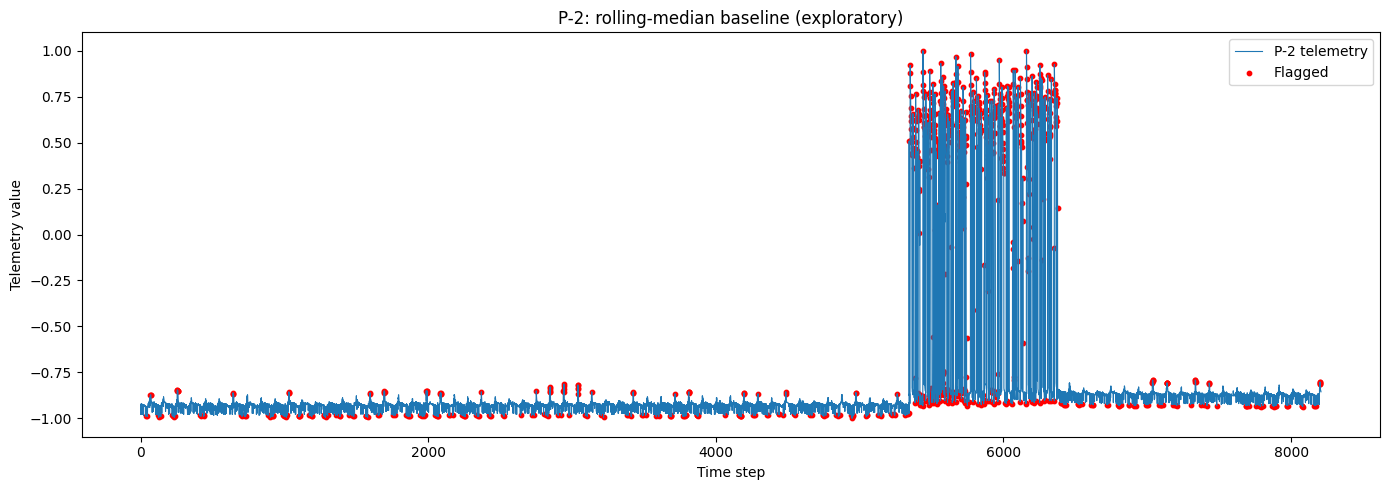

In [7]:
plt.figure(figsize=(14, 5))
plt.plot(signal, linewidth=0.8, label="P-2 telemetry")
plt.scatter(np.where(predictions)[0], signal[predictions], color="red", s=10, label="Flagged")
plt.title("P-2: rolling-median baseline (exploratory)")
plt.xlabel("Time step")
plt.ylabel("Telemetry value")
plt.legend()
plt.tight_layout()
plt.show()

### Count hits and false alarms

**What it does:** builds a point-level truth mask (`True` wherever any labeled interval covers a time step) and counts flagged points inside and outside it.

**Why:** the plot suggests false positives, and this puts a number on it. The mask is the *union* of both P-2 intervals, used only for this count. The interval list itself is untouched.

**Expect:** 1276 labeled points, 669 flagged inside, 319 flagged outside. That gives rough point-level precision of 0.68 and recall of 0.52, but on a test-calibrated threshold, so these are for diagnosis only.

In [8]:
truth = np.zeros(len(signal), dtype=bool)
for start, end in intervals_p2:
    truth[start:end + 1] = True

print("labeled points:         ", truth.sum())
print("flagged inside labels:  ", (predictions & truth).sum())
print("flagged outside labels: ", (predictions & ~truth).sum())

labeled points:          1276
flagged inside labels:   669
flagged outside labels:  319


### Where do the flags fall?

**What it does:** splits the test signal at the label boundaries and reports the fraction flagged in each region.

**Why:** it separates the two failure modes: false alarms in quiet regions and misses inside the burst.

**Expect (from the earlier run):**

| Region | Flagged |
|---|---|
| before 5300 | 4.6% |
| 5300-5349 | 10.0% (only 50 points) |
| 5350-6419 | 61.3% |
| 6420-6575 | 5.1% |
| after 6575 | 4.7% |

What this showed: the false-alarm rate is flat at about 4.6% in quiet regions, which points to a threshold that is too low, not to structure in the signal. About 39% of burst points are missed. The part of the label after about 6420 is flagged no more than quiet signal, so the detector sees nothing unusual there. Whether the label or the detector is "wrong" there is unknown.

In [9]:
regions = {
    "before 5300": (0, 5299),
    "5300-5349":   (5300, 5349),
    "5350-6419":   (5350, 6419),
    "6420-6575":   (6420, 6575),
    "after 6575":  (6576, len(signal) - 1),
}

for name, (a, b) in regions.items():
    n = b - a + 1
    flagged = predictions[a:b + 1].sum()
    print(f"{name:12s} length={n:5d}  flagged={flagged:4d}  ({flagged / n:.1%})")

before 5300  length= 5300  flagged= 242  (4.6%)
5300-5349    length=   50  flagged=   5  (10.0%)
5350-6419    length= 1070  flagged= 656  (61.3%)
6420-6575    length=  156  flagged=   8  (5.1%)
after 6575   length= 1633  flagged=  77  (4.7%)


### Train versus quiet test, and quantization

**What it does:** prints min, max, mean, std and the number of distinct values for the training signal, the quiet part of the test signal (before any label starts), and the whole test signal. It then counts points whose deviation lies between the threshold and the exact 90th percentile.

**Why:** two questions.
- Does quiet test look like train? If not, a threshold learned on train won't transfer.
- Is the signal quantized (few distinct values)? If so, deviations take only a few levels and thresholds behave like staircases.

**Correction to the old cell:** it used `0.0588` as the upper edge, a rounded 90th percentile, and so counted 0. Here the edge is the exact `np.quantile(deviation, 0.9)`.

**Expect:** about 33 distinct values in train and 36 in quiet test, so the signal is quantized. Train mean about -0.943 and quiet-test mean about -0.929: a small shift, observed but not evidence of drift. Because of quantization, I expect the band count to be roughly 160 with only one or two distinct deviation values (a hypothesis; the output will tell).

In [10]:
quiet = test_p2[:5300]   # test signal before any labeled interval starts

def summary(name, x):
    print(f"{name:12s} n={len(x):5d}  min={x.min():.4f}  max={x.max():.4f}  "
          f"mean={x.mean():.4f}  std={x.std():.4f}  unique={len(np.unique(x))}")

summary("train", train_p2)
summary("test 0-5299", quiet)
summary("test all", test_p2)

q90 = np.quantile(deviation, 0.9)
band = (deviation > threshold) & (deviation <= q90)
print("threshold:", round(threshold, 5), "| exact 90th percentile:", round(q90, 5))
print("points between them:", band.sum(), "| distinct deviation values there:", len(np.unique(deviation[band])))

train        n= 2821  min=-1.0000  max=-0.8400  mean=-0.9433  std=0.0284  unique=33
test 0-5299  n= 5300  min=-1.0000  max=-0.8128  mean=-0.9292  std=0.0226  unique=36
test all     n= 8209  min=-1.0000  max=1.0000  mean=-0.8273  std=0.3488  unique=202
threshold: 0.05827 | exact 90th percentile: 0.05882
points between them: 196 | distinct deviation values there: 3


## 5. Protocol for a defensible baseline

What we change, and why.

| Question | Exploratory version | Protocol version |
|---|---|---|
| Window | centered (uses the future) | **trailing**, past only (online) |
| Window start | `min_periods=1`, invented values | first `window` points are `NaN` (no verdict) |
| Threshold source | test signal (contains the anomaly) | **training signal only** (fit on first 80%, choose on last 20%) |
| Threshold rule | median + 6 x 1.4826 x MAD (unreliable on quantized, skewed data) | a quantile of training deviations (to be chosen) |
| Test labels | used while looking at results | used **only** for final scoring |
| Evaluation | rough point counts | point-level **and** event-level, each P-2 label scored separately |

Rule for the rest of the project: design choices come from principle and from training or validation data, never from sweeping parameters until the test numbers look good.

## 6. Trailing-window deviation

**What it does:** runs `trailing_deviation` (in `src/starling/detectors.py`) on the P-2 train and test signals. For each time step it compares the value with the median of the previous 101 values, never including the current or any future value.

**Why:** this is the online version of the same idea. Train deviations describe what "normal" looks like; that is what the threshold will be built from. Test deviations will show the burst as much larger upper quantiles.

**Needs:** the file `src/starling/detectors.py` containing `trailing_deviation` (created in the previous step). If the import fails, create that file first.

**Expect:** 101 `NaN` values in each signal (the warm-up). Train quantiles small and close together. Test 99% and 99.9% quantiles much larger than train's, because of the burst.

In [12]:
from starling.detectors import trailing_deviation

dev_train = trailing_deviation(train_p2)
dev_test = trailing_deviation(test_p2)

print("NaN count  train:", np.isnan(dev_train).sum(), " test:", np.isnan(dev_test).sum())
print("train deviation quantiles (50/90/99/99.9%):",
      np.nanquantile(dev_train, [0.5, 0.9, 0.99, 0.999]).round(4))
print("test  deviation quantiles (50/90/99/99.9%):",
      np.nanquantile(dev_test, [0.5, 0.9, 0.99, 0.999]).round(4))

NaN count  train: 101  test: 101
train deviation quantiles (50/90/99/99.9%): [0.0222 0.0444 0.0667 0.0857]
test  deviation quantiles (50/90/99/99.9%): [0.0107 0.0588 1.5829 1.7576]


## 7. Next steps (planned, not done)

1. Split train in time order (first 80% fit, last 20% validation) and choose a threshold from training deviations only.
2. Apply it to test and look at the flags, without tuning on test labels.
3. Write `src/starling/evaluation.py`: point-level precision, recall and F1, plus event-level scoring, with each P-2 label scored separately.
4. Investigate the M-6 mismatch and the out-of-range channels, and document each decision.
5. Stronger baseline: a simple forecasting model (predict the next value from a window, flag large errors), with scaling fitted on training data only.
6. MLflow tracking, then static vs periodic vs drift-aware retraining under identical conditions.
7. Airflow and Docker, after the experiments are sound.

In [19]:
import numpy as np
from starling.data_load import load_channel
from starling.splitter import time_split
from starling.detectors import trailing_deviation

train_p2, test_p2, intervals_p2 = load_channel("P-2", data_dir="data")

fit, val = time_split(train_p2)
print("signal   fit/val:", len(fit), len(val))
assert np.array_equal(np.concatenate([fit, val]), train_p2)   # nothing lost or reordered

dev_train = trailing_deviation(train_p2)
dev_fit, dev_val = time_split(dev_train)
print("scores   fit/val:", len(dev_fit), len(dev_val))
print("NaN in dev_fit:", np.isnan(dev_fit).sum(), "| NaN in dev_val:", np.isnan(dev_val).sum())

signal   fit/val: 2256 565
scores   fit/val: 2256 565
NaN in dev_fit: 101 | NaN in dev_val: 0


In [20]:
from starling.thresholds import fit_threshold, flag

valid_fit = ~np.isnan(dev_fit)
print(f"{'q':>6} {'threshold':>10} {'fit flag rate':>14} {'val flag rate':>14}")
for q in [0.90, 0.99, 0.995, 0.999, 1.0]:
    t = fit_threshold(dev_fit, q)
    fit_rate = flag(dev_fit, t)[valid_fit].mean()
    val_rate = flag(dev_val, t).mean()
    print(f"{q:6.3f} {t:10.5f} {fit_rate:14.2%} {val_rate:14.2%}")

     q  threshold  fit flag rate  val flag rate
 0.900    0.04444          9.65%          9.56%
 0.990    0.06667          0.97%          0.88%
 0.995    0.08000          0.37%          0.53%
 0.999    0.08820          0.14%          0.00%
 1.000    0.10667          0.00%          0.00%


In [21]:
import numpy as np
from starling.data_load import load_channel
from starling.splitter import time_split
from starling.detectors import trailing_deviation
from starling.thresholds import fit_threshold, flag

Q = 0.99   # chosen from the validation table, before looking at test

train_p2, test_p2, intervals_p2 = load_channel("P-2", data_dir="data")
dev_fit, dev_val = time_split(trailing_deviation(train_p2))
threshold = fit_threshold(dev_fit, Q)

dev_test = trailing_deviation(test_p2)
pred = flag(dev_test, threshold)

truth = np.zeros(len(test_p2), dtype=bool)
for s, e in intervals_p2:
    truth[s:e + 1] = True

print("threshold:", round(threshold, 5))
print("flagged:", pred.sum(), "| inside labels:", (pred & truth).sum(),
      "| outside labels:", (pred & ~truth).sum())

regions = {"before 5300": (0, 5299), "5300-5349": (5300, 5349), "5350-6419": (5350, 6419),
           "6420-6575": (6420, 6575), "after 6575": (6576, len(test_p2) - 1)}
for name, (a, b) in regions.items():
    n = b - a + 1
    k = pred[a:b + 1].sum()
    print(f"{name:12s} length={n:5d}  flagged={k:4d}  ({k / n:.1%})")

threshold: 0.06667
flagged: 682 | inside labels: 635 | outside labels: 47
before 5300  length= 5300  flagged=  40  (0.8%)
5300-5349    length=   50  flagged=   1  (2.0%)
5350-6419    length= 1070  flagged= 631  (59.0%)
6420-6575    length=  156  flagged=   3  (1.9%)
after 6575   length= 1633  flagged=   7  (0.4%)


In [22]:
import numpy as np
from starling.data_load import load_channel
from starling.splitter import time_split
from starling.detectors import trailing_deviation
from starling.thresholds import fit_threshold, flag
from starling.evaluation import point_metrics, event_metrics, count_segments

train_p2, test_p2, intervals_p2 = load_channel("P-2", data_dir="data")
dev_fit, _ = time_split(trailing_deviation(train_p2))
threshold = fit_threshold(dev_fit, 0.99)

dev_test = trailing_deviation(test_p2)
pred = flag(dev_test, threshold)
valid = ~np.isnan(dev_test)

truth = np.zeros(len(test_p2), dtype=bool)
for s, e in intervals_p2:
    truth[s:e + 1] = True

m = point_metrics(pred, truth, valid)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items()})
for ev in event_metrics(pred, intervals_p2):
    print(ev)
print("false-alarm segments:", count_segments(pred & ~truth))

{'tp': 635, 'fp': 47, 'fn': 641, 'tn': 6785, 'precision': 0.9311, 'recall': 0.4976, 'f1': 0.6486, 'fpr': 0.0069}
{'interval': (5350, 6575), 'detected': True, 'delay': 1, 'flagged_fraction': 0.5171288743882545}
{'interval': (5300, 6420), 'detected': True, 'delay': 44, 'flagged_fraction': 0.5637823371989296}
false-alarm segments: 27


In [23]:
from starling.pipeline import run_channel

r1 = run_channel("P-2")
print(r1["params"])
print("threshold:", round(r1["threshold"], 5))
print(r1["point"])
print(r1["events"])
print("false-alarm segments:", r1["false_alarm_segments"])

r2 = run_channel("P-2")
print("reproducible:", r1 == r2)

{'chan_id': 'P-2', 'window': 101, 'q': 0.99, 'fit_frac': 0.8}
threshold: 0.06667
{'tp': 635, 'fp': 47, 'fn': 641, 'tn': 6785, 'precision': 0.9310850439882697, 'recall': 0.49764890282131663, 'f1': 0.6486210418794689, 'fpr': 0.006879391100702576}
[{'interval': (5350, 6575), 'detected': True, 'delay': 1, 'flagged_fraction': 0.5171288743882545}, {'interval': (5300, 6420), 'detected': True, 'delay': 44, 'flagged_fraction': 0.5637823371989296}]
false-alarm segments: 27
reproducible: True


In [24]:
import pandas as pd
from starling.pipeline import run_channel

labels = pd.read_csv("data/labeled_anomalies.csv")
chans = sorted(labels["chan_id"].unique())

rows, failed = [], {}
for c in chans:
    try:
        r = run_channel(c)
        rows.append({"chan": c, **r["point"],
                     "segments": r["false_alarm_segments"],
                     "detected": sum(e["detected"] for e in r["events"]),
                     "n_events": len(r["events"])})
    except Exception as e:
        failed[c] = str(e)[:80]

res = pd.DataFrame(rows)
print(len(chans), "channels | ran:", len(res), "| failed:", len(failed))
print(failed)
print(res[["precision", "recall", "f1", "fpr"]].describe().round(3))

81 channels | ran: 81 | failed: 0
{}
       precision  recall      f1     fpr
count     81.000  81.000  81.000  81.000
mean       0.506   0.215   0.183   0.049
std        0.434   0.310   0.254   0.160
min        0.000   0.000   0.000   0.000
25%        0.020   0.003   0.006   0.000
50%        0.500   0.034   0.061   0.000
75%        1.000   0.329   0.278   0.013
max        1.000   1.000   0.998   0.902


In [25]:
import numpy as np
from starling.data_load import load_channel

extra = []
for c in res["chan"]:
    tr, te, iv = load_channel(c, data_dir="data")
    truth = np.zeros(len(te), bool)
    for s, e in iv:
        truth[s:e + 1] = True
    extra.append({"chan": c, "train_std": tr.std(), "train_unique": len(np.unique(tr)),
                  "label_frac": truth.mean()})

res2 = res.merge(pd.DataFrame(extra), on="chan")

print("events detected:", res2["detected"].sum(), "of", res2["n_events"].sum())
print("channels with no flags (tp+fp==0):", ((res2.tp + res2.fp) == 0).sum())
print("channels with constant train signal:", (res2.train_std == 0).sum())
cols = ["chan", "fpr", "precision", "recall", "f1", "train_std", "train_unique", "label_frac"]
print("\nhighest false-positive rate:")
print(res2.sort_values("fpr", ascending=False)[cols].head(10).round(3).to_string(index=False))
print("\nhighest F1:")
print(res2.sort_values("f1", ascending=False)[cols].head(5).round(3).to_string(index=False))

events detected: 76 of 105
channels with no flags (tp+fp==0): 13
channels with constant train signal: 14

highest false-positive rate:
chan   fpr  precision  recall    f1  train_std  train_unique  label_frac
P-14 0.902      0.032   0.950 0.061      0.000            36       0.030
 C-2 0.885      0.078   0.985 0.144      0.000             1       0.067
 T-9 0.547      0.188   1.000 0.317      0.202             4       0.102
 D-5 0.381      0.014   0.765 0.027      0.000           104       0.007
 M-1 0.300      0.043   0.012 0.019      0.692          1183       0.501
 A-5 0.198      0.049   0.902 0.093      0.000            19       0.011
P-10 0.187      0.081   0.740 0.146      0.001            39       0.021
 M-6 0.090      0.257   0.304 0.278      0.000             1       0.088
 M-2 0.089      0.815   0.356 0.495      0.340          1243       0.501
P-15 0.073      0.065   0.667 0.119      0.036           760       0.007

highest F1:
chan   fpr  precision  recall    f1  train_std  t

In [26]:
from starling.pipeline import run_channel

res2["threshold"] = [run_channel(c)["threshold"] for c in res2["chan"]]
res2["zero_thr"] = res2["threshold"] == 0

print("channels with threshold exactly 0:", res2["zero_thr"].sum())
print(res2.groupby("zero_thr").agg(
    n=("chan", "count"),
    median_fpr=("fpr", "median"),
    share_fpr_over_5pct=("fpr", lambda s: (s > 0.05).mean()),
    median_f1=("f1", "median"),
).round(3))

cols = ["chan", "threshold", "fpr", "precision", "label_frac"]
print(res2.sort_values("fpr", ascending=False)[cols].head(10).round(5).to_string(index=False))

channels with threshold exactly 0: 19
           n  median_fpr  share_fpr_over_5pct  median_f1
zero_thr                                                
False     62       0.002                0.113      0.029
True      19       0.000                0.158      0.262
chan  threshold     fpr  precision  label_frac
P-14    0.00022 0.90237    0.03172     0.02967
 C-2    0.00000 0.88527    0.07759     0.06680
 T-9    0.00000 0.54700    0.18824     0.10219
 D-5    0.00085 0.38109    0.01350     0.00669
 M-1    1.63526 0.29952    0.04321     0.50110
 A-5    0.00016 0.19753    0.04878     0.01087
P-10    0.00311 0.18712    0.08117     0.02148
 M-6    0.00000 0.08998    0.25701     0.08834
 M-2    1.37129 0.08889    0.81526     0.50110
P-15    0.10954 0.07315    0.06542     0.00735


In [27]:
import numpy as np
import pandas as pd
from starling.data_load import load_channel
from starling.detectors import trailing_deviation

def auc(scores, truth):
    """P(random anomalous point scores higher than random normal point); ties count 1/2."""
    pos = int(truth.sum())
    neg = len(truth) - pos
    if pos == 0 or neg == 0:
        return np.nan
    ranks = pd.Series(scores).rank().to_numpy()   # average ranks handle tied values
    return (ranks[truth].sum() - pos * (pos + 1) / 2) / (pos * neg)

aucs = []
for c in res2["chan"]:
    _, te, iv = load_channel(c, data_dir="data")
    dev = trailing_deviation(te)
    ok = ~np.isnan(dev)
    truth = np.zeros(len(te), bool)
    for s, e in iv:
        truth[s:e + 1] = True
    aucs.append(auc(dev[ok], truth[ok]))
res2["auc"] = aucs

print(res2["auc"].describe().round(3))
print("share with AUC > 0.7:", round((res2["auc"] > 0.7).mean(), 3))
print("share with AUC < 0.5:", round((res2["auc"] < 0.5).mean(), 3))
print(res2.groupby("zero_thr")["auc"].median().round(3))
print("zero threshold but train_std > 0:", res2[res2.zero_thr & (res2.train_std > 0)]["chan"].tolist())

count    81.000
mean      0.604
std       0.179
min       0.090
25%       0.506
50%       0.585
75%       0.705
max       1.000
Name: auc, dtype: float64
share with AUC > 0.7: 0.259
share with AUC < 0.5: 0.235
zero_thr
False    0.583
True     0.596
Name: auc, dtype: float64
zero threshold but train_std > 0: ['A-1', 'G-3', 'G-7', 'R-1', 'T-9']


In [29]:
import numpy as np
from starling.data_load import load_channel
from starling.splitter import time_split
from starling.detectors import trailing_deviation
from starling.thresholds import fit_threshold, flag
from starling.models import make_windows, Linear_model
from starling.evaluation import point_metrics, auc_score

train_p2, test_p2, intervals_p2 = load_channel("P-2", data_dir="data")
truth = np.zeros(len(test_p2), dtype=bool)
for s, e in intervals_p2:
    truth[s:e + 1] = True
fit_sig, _ = time_split(train_p2)

# Check 1: sklearn gives the same errors as a hand-written least-squares fit
X, y = make_windows(fit_sig, 32)
X1 = np.hstack([X, np.ones((len(X), 1))])
coef, *_ = np.linalg.lstsq(X1, y, rcond=None)
err_numpy = np.abs(y - X1 @ coef)
model = Linear_model(lag=32).fit(fit_sig)
print("same errors:", np.allclose(err_numpy, model.score(fit_sig)[32:], atol=1e-8))

# Check 2: both scorers through the identical pipeline
scorers = {
    "rolling median": lambda x: trailing_deviation(x, 101),
    "linear forecast": model.score,
}
for name, scorer in scorers.items():
    err_fit, err_val = time_split(scorer(train_p2))
    thr = fit_threshold(err_fit, 0.99)
    test_scores = scorer(test_p2)
    pred = flag(test_scores, thr)
    m = point_metrics(pred, truth, ~np.isnan(test_scores))
    print(f"{name:16s} thr={thr:.5f}  val flag rate={flag(err_val, thr).mean():.2%}  "
          f"AUC={auc_score(test_scores, truth):.3f}  "
          f"P={m['precision']:.3f}  R={m['recall']:.3f}  F1={m['f1']:.3f}  FPR={m['fpr']:.4f}")

same errors: True
rolling median   thr=0.06667  val flag rate=0.88%  AUC=0.811  P=0.931  R=0.498  F1=0.649  FPR=0.0069
linear forecast  thr=0.04657  val flag rate=0.35%  AUC=0.925  P=0.773  R=0.784  F1=0.779  FPR=0.0426


In [30]:
import numpy as np
from starling.data_load import load_channel
from starling.splitter import time_split
from starling.detectors import trailing_deviation
from starling.thresholds import fit_threshold, flag
from starling.models import make_windows, Linear_model

train_p2, test_p2, intervals_p2 = load_channel("P-2", data_dir="data")
fit_sig, _ = time_split(train_p2)
model = Linear_model(lag=32).fit(fit_sig)

scorers = {"rolling median": lambda x: trailing_deviation(x, 101), "linear forecast": model.score}
preds = {}
for name, scorer in scorers.items():
    err_fit, _ = time_split(scorer(train_p2))
    preds[name] = flag(scorer(test_p2), fit_threshold(err_fit, 0.99))

regions = {"before 5300": (0, 5299), "5300-5349": (5300, 5349), "5350-6419": (5350, 6419),
           "6420-6575": (6420, 6575), "after 6575": (6576, len(test_p2) - 1)}
print(f"{'region':12s} {'mean level':>10s} {'rolling median':>15s} {'linear forecast':>16s}")
for rname, (a, b) in regions.items():
    print(f"{rname:12s} {test_p2[a:b+1].mean():10.4f} "
          f"{preds['rolling median'][a:b+1].mean():15.1%} {preds['linear forecast'][a:b+1].mean():16.1%}")

def resid_stats(x, a, b):
    X, y = make_windows(x, 32)
    r = y - model.model.predict(X)     # r[i] belongs to time step i + 32
    t = np.arange(32, len(x))
    m = (t >= a) & (t <= b)
    return r[m].mean(), np.abs(r[m]).mean()

print("\nlinear model residuals (mean signed / mean absolute):")
for label, x, a, b in [("train fit part", train_p2, 0, len(fit_sig) - 1),
                       ("test before 5300", test_p2, 0, 5299),
                       ("test after 6575", test_p2, 6576, len(test_p2) - 1)]:
    s, ab = resid_stats(x, a, b)
    print(f"{label:17s} signed={s:+.5f}  abs={ab:.5f}")

region       mean level  rolling median  linear forecast
before 5300     -0.9292            0.8%             4.3%
5300-5349       -0.9065            2.0%            12.0%
5350-6419       -0.2435           59.0%            91.8%
6420-6575       -0.8683            1.9%             8.3%
after 6575      -0.8730            0.4%             4.1%

linear model residuals (mean signed / mean absolute):
train fit part    signed=-0.00000  abs=0.01663
test before 5300  signed=+0.00434  abs=0.01714
test after 6575   signed=+0.02217  abs=0.02833


In [31]:
import numpy as np
from sklearn.metrics import roc_curve
from starling.data_load import load_channel
from starling.splitter import time_split
from starling.detectors import trailing_deviation
from starling.thresholds import fit_threshold, flag
from starling.models import Linear_model

train_p2, test_p2, intervals_p2 = load_channel("P-2", data_dir="data")
truth = np.zeros(len(test_p2), dtype=bool)
for s, e in intervals_p2:
    truth[s:e + 1] = True
fit_sig, _ = time_split(train_p2)
model = Linear_model(lag=32).fit(fit_sig)
scorers = {"rolling median": lambda x: trailing_deviation(x, 101), "linear forecast": model.score}

# 1. error tails: is the quiet test tail heavier than train?
err_fit, err_val = time_split(model.score(train_p2))
err_test = model.score(test_p2)
print("linear-model error quantiles (50/90/99/99.9%):")
for label, e in [("train fit", err_fit), ("train val", err_val),
                 ("test 0-5299", err_test[:5300]), ("test 6576-end", err_test[6576:])]:
    print(f"  {label:14s}", np.nanquantile(e, [0.5, 0.9, 0.99, 0.999]).round(4))

# 2. false-alarm rate over time, unlabeled points only, bins of 500
thr, sc = {}, {}
for name, scorer in scorers.items():
    e_fit, _ = time_split(scorer(train_p2))
    thr[name] = fit_threshold(e_fit, 0.99)
    sc[name] = scorer(test_p2)
both_ok = ~np.isnan(sc["linear forecast"]) & ~np.isnan(sc["rolling median"])

print("\nfalse-alarm rate per 500-step bin (unlabeled points):")
print(f"{'bin':>12s} {'n':>5s} {'rolling median':>15s} {'linear forecast':>16s}")
for a in range(0, len(test_p2), 500):
    b = min(a + 500, len(test_p2))
    sel = ~truth[a:b] & both_ok[a:b]
    if sel.sum() == 0:
        continue
    r = [flag(sc[nm][a:b], thr[nm])[sel].mean() for nm in scorers]
    print(f"{a:5d}-{b - 1:5d} {sel.sum():5d} {r[0]:15.1%} {r[1]:16.1%}")

# 3. recall at FPR <= 1% (threshold-free view of the two scores)
print("\nrecall at FPR <= 1%:")
for name in scorers:
    fpr, tpr, _ = roc_curve(truth[both_ok], sc[name][both_ok])
    print(f"  {name:16s} recall={tpr[fpr <= 0.01].max():.3f}")

linear-model error quantiles (50/90/99/99.9%):
  train fit      [0.0141 0.034  0.0466 0.0524]
  train val      [0.0164 0.0351 0.0456 0.0498]
  test 0-5299    [0.0141 0.0378 0.055  0.0758]
  test 6576-end  [0.0282 0.0413 0.0648 0.0883]

false-alarm rate per 500-step bin (unlabeled points):
         bin     n  rolling median  linear forecast
    0-  499   399            2.0%             4.3%
  500-  999   500            0.4%             4.8%
 1000- 1499   500            0.2%             4.2%
 1500- 1999   500            1.4%             4.4%
 2000- 2499   500            0.2%             5.2%
 2500- 2999   500            2.0%             4.4%
 3000- 3499   500            1.4%             5.4%
 3500- 3999   500            0.6%             4.8%
 4000- 4499   500            0.0%             3.4%
 4500- 4999   500            0.2%             3.8%
 5000- 5499   300            0.0%             2.0%
 6500- 6999   424            0.0%             3.1%
 7000- 7499   500            1.0%             

In [32]:
import numpy as np
import pandas as pd
from starling.data_load import load_channel
from starling.pipeline import run_channel

# sanity check: must reproduce the P-2 numbers
for m in ["rolling_median", "linear"]:
    r = run_channel("P-2", method=m)
    print(m, round(r["threshold"], 5), round(r["point"]["f1"], 3), round(r["auc"], 3))

labels = pd.read_csv("data/labeled_anomalies.csv")
chans = sorted(labels["chan_id"].unique())

rows, failed = [], {}
for method in ["rolling_median", "linear"]:
    for c in chans:
        try:
            r = run_channel(c, method=method)
        except Exception as e:
            failed[(method, c)] = str(e)[:80]
            continue
        rows.append({"method": method, "chan": c, "threshold": r["threshold"],
                     **r["point"], "auc": r["auc"],
                     "detected": sum(ev["detected"] for ev in r["events"]),
                     "n_events": len(r["events"])})
res = pd.DataFrame(rows)
print("\nfailed:", failed)

summary = res.groupby("method").agg(
    channels=("chan", "count"),
    median_auc=("auc", "median"),
    median_f1=("f1", "median"),
    mean_f1=("f1", "mean"),
    median_recall=("recall", "median"),
    median_fpr=("fpr", "median"),
    share_fpr_over_5pct=("fpr", lambda s: (s > 0.05).mean()),
    no_flag_channels=("precision", lambda s: s.isna().sum()),
    events_detected=("detected", "sum"),
    events_total=("n_events", "sum"),
)
print(summary.round(3).T)

wide = res.pivot(index="chan", columns="method", values="auc")
d = wide["linear"] - wide["rolling_median"]
print("\nlinear AUC higher on", (d > 0).sum(), "channels, lower on", (d < 0).sum(),
      "| median difference:", round(d.median(), 3))

# does the share of unlabeled test points outside the train range track the false-alarm rate?
extra = []
for c in chans:
    tr, te, iv = load_channel(c, data_dir="data")
    truth = np.zeros(len(te), bool)
    for s, e in iv:
        truth[s:e + 1] = True
    outside = (te < tr.min()) | (te > tr.max())
    extra.append({"chan": c, "oor": outside[~truth].mean()})
extra = pd.DataFrame(extra)
for m in ["rolling_median", "linear"]:
    sub = res[(res.method == m) & (res.threshold > 0)].merge(extra, on="chan")
    print(f"{m:15s} n={len(sub)}  Spearman(out-of-range share, FPR) =",
          round(sub["oor"].corr(sub["fpr"], method="spearman"), 3))

rolling_median 0.06667 0.649 0.811
linear 0.04657 0.779 0.925

failed: {}
method                linear  rolling_median
channels              81.000          81.000
median_auc             0.636           0.585
median_f1              0.048           0.061
mean_f1                0.208           0.183
median_recall          0.074           0.034
median_fpr             0.008           0.000
share_fpr_over_5pct    0.222           0.123
no_flag_channels       0.000           0.000
events_detected       96.000          76.000
events_total         105.000         105.000

linear AUC higher on 45 channels, lower on 30 | median difference: 0.017
rolling_median  n=62  Spearman(out-of-range share, FPR) = 0.618
linear          n=66  Spearman(out-of-range share, FPR) = 0.452


In [33]:
from scipy.stats import wilcoxon

wide = res.pivot(index="chan", columns="method", values="auc")
d = (wide["linear"] - wide["rolling_median"]).dropna()
print("channels compared:", len(d), "| exact ties:", int((d == 0).sum()))
print("Wilcoxon signed-rank p-value:", round(wilcoxon(d[d != 0]).pvalue, 4))
print("\nAUC within 0.05 of chance:\n", ((wide - 0.5).abs() < 0.05).sum())
print("AUC below 0.5:\n", (wide < 0.5).sum())

wf = res.pivot(index="chan", columns="method", values="fpr")
print("\nFPR > 5% for linear but not for rolling median:",
      int(((wf["linear"] > 0.05) & (wf["rolling_median"] <= 0.05)).sum()))
print("FPR > 5% for rolling median but not for linear:",
      int(((wf["rolling_median"] > 0.05) & (wf["linear"] <= 0.05)).sum()))

print("\nSpearman(out-of-range share, FPR):")
for m in ["rolling_median", "linear"]:
    sub = res[(res.method == m) & (res.threshold > 0)].merge(extra, on="chan")
    print(f"  {m:15s} n={len(sub)}  {sub['oor'].corr(sub['fpr'], method='spearman'):.3f}")

channels compared: 81 | exact ties: 6
Wilcoxon signed-rank p-value: 0.0165

AUC within 0.05 of chance:
 method
linear            19
rolling_median    24
dtype: int64
AUC below 0.5:
 method
linear            16
rolling_median    19
dtype: int64

FPR > 5% for linear but not for rolling median: 11
FPR > 5% for rolling median but not for linear: 3

Spearman(out-of-range share, FPR):
  rolling_median  n=62  0.618
  linear          n=66  0.452


In [34]:
import mlflow
from starling.pipeline import run_channel
from starling.tracking import log_run

for m in ["rolling_median", "linear"]:
    log_run(run_channel("P-2", method=m))

mlflow.set_tracking_uri("sqlite:///mlflow.db")
df = mlflow.search_runs(experiment_names=["starling-baselines"])
print(df[["tags.mlflow.runName", "params.method", "params.q",
          "metrics.f1", "metrics.auc", "metrics.fpr"]])

2026/10/26 13:07:43 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/26 13:07:43 INFO mlflow.store.db.utils: Updating database tables
2026/10/26 13:07:44 INFO mlflow.tracking.fluent: Experiment with name 'starling-base' does not exist. Creating a new experiment.
2026/10/26 13:07:45 WARNING mlflow.tracking.fluent: Cannot retrieve experiment by name starling-baselines


KeyError: "None of [Index(['tags.mlflow.runName', 'params.method', 'params.q', 'metrics.f1',\n       'metrics.auc', 'metrics.fpr'],\n      dtype='object')] are in the [columns]"